# Digital Banking Customer Risk Classification
**Project:** Early-warning classification system for high-risk customers

## Objective
Predict `risk_status` (0 = Low Risk, 1 = High Risk), address class imbalance, compare Logistic Regression, Decision Tree and Random Forest, tune models, and select a model with emphasis on minimizing false negatives.


## Business framing
- **False negative (Type-II error):** a genuinely high-risk customer predicted as low risk. This is especially costly because the bank may miss a default/fraud warning.
- **False positive (Type-I error):** a low-risk customer flagged as high risk. This can cause unnecessary reviews or customer friction.
- The final choice should prioritize high-risk recall while checking precision, F1, ROC-AUC and operational review capacity.

## Part A — Conceptual understanding

1. **Logistic Regression:** A supervised classification algorithm that estimates the probability of a class using the logistic (sigmoid) function. It is suitable for binary classification because its output is a probability between 0 and 1, which can be converted into a class using a decision threshold.
2. **Classification metrics:** Accuracy is the fraction of all predictions that are correct; precision measures how many predicted positives are truly positive; recall measures how many actual positives are found; F1 is their harmonic mean. Accuracy alone can be misleading when the risky class is rare, because predicting everyone as low-risk may still produce high accuracy.
3. **Type-I and Type-II errors:** Type-I error (false positive) means a low-risk customer is incorrectly flagged as high-risk. Type-II error (false negative) means a high-risk customer is incorrectly classified as low-risk; this is often more costly for early-warning systems.
4. **Precision, Recall, F1, TPR and FPR:** Precision = TP/(TP+FP); Recall/TPR = TP/(TP+FN); F1 is the harmonic mean of precision and recall. FPR = FP/(FP+TN), the share of actual low-risk customers incorrectly flagged.
5. **ROC-AUC:** The ROC curve plots TPR against FPR across classification thresholds. AUC summarizes ranking ability: 1 is perfect, 0.5 is approximately random. It is threshold-independent, but should be considered alongside precision-recall metrics for rare positives.
6. **Imbalanced data:** A model can minimize overall error by favoring the majority class, often missing the minority high-risk customers. This makes accuracy look good while minority recall and F1 remain poor; resampling, class weights and suitable metrics help address this.

## Part B — Imports and data loading

In [2]:
# If needed, install once:
# %pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve, classification_report
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

RANDOM_STATE = 42
DATA_PATH = "Risk_Alert_Classifier_Dataset_4600 - Risk_Alert_Classifier_Dataset_4600.csv.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Shape: (4600, 19)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0



Columns: ['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr', 'risk_status']


## Initial data inspection and target preparation

`customer_id` is an identifier, not a predictive feature. `last_transaction_date` is converted into elapsed days relative to the latest date in the dataset, then the raw date is removed. This avoids treating an arbitrary date string as a category.

In [3]:
print(df.info())
display(df.describe(include="all").T)
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

TARGET = "risk_status"
required = {
    "customer_id", "age", "gender", "region", "employment_type", "annual_income_inr",
    "credit_score", "credit_utilization_ratio", "missed_payments_12m",
    "avg_late_payment_days", "monthly_transaction_count", "monthly_spend_inr",
    "cash_advance_count_6m", "complaints_last_6m", "failed_login_attempts_3m",
    "account_tenure_months", "last_transaction_date", "debt_balance_inr", TARGET
}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing_cols)}")

# Normalize target labels if they are stored as strings.
if df[TARGET].dtype == "object":
    target_map = {"0": 0, "1": 1, "low risk": 0, "high risk": 1,
                  "low-risk": 0, "high-risk": 1}
    df[TARGET] = df[TARGET].astype(str).str.strip().str.lower().map(target_map)

df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("risk_status must contain only 0 (Low Risk) and 1 (High Risk).")

# Feature engineering for transaction recency.
df["last_transaction_date"] = pd.to_datetime(df["last_transaction_date"], errors="coerce")
reference_date = df["last_transaction_date"].max()
df["days_since_last_transaction"] = (
    reference_date - df["last_transaction_date"]
).dt.days
df = df.drop(columns=["customer_id", "last_transaction_date"])

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Target distribution:")
display(y.value_counts().rename(index={0:"Low Risk (0)", 1:"High Risk (1)"}).to_frame("count"))
display((y.value_counts(normalize=True)*100).rename(index={0:"Low Risk (0)", 1:"High Risk (1)"}).to_frame("percent"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,4600.0,NaN,NaN,NaN,502300.5,1328.049949,500001.0,501150.75,502300.5,503450.25,504600.0
age,4460.0,NaN,NaN,NaN,36.360314,10.670375,18.0,28.0,36.0,44.0,75.0
gender,4600,3,Male,2358,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,4498,5,South,1057,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,4456,5,Salaried,2354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income_inr,4434.0,NaN,NaN,NaN,41753.518268,17740.750972,15000.0,28980.0,38932.5,51282.5,163002.0
credit_score,4384.0,NaN,NaN,NaN,677.784443,64.888787,405.0,638.0,682.0,721.25,850.0
credit_utilization_ratio,4453.0,NaN,NaN,NaN,0.394721,0.205771,0.002,0.232,0.37,0.531,0.978
missed_payments_12m,4600.0,NaN,NaN,NaN,0.92413,1.300018,0.0,0.0,1.0,1.0,10.0
avg_late_payment_days,4600.0,NaN,NaN,NaN,5.538696,5.624891,0.1,2.1,3.9,6.6,47.1



Missing values:


,missing_count
credit_score,216
annual_income_inr,166
credit_utilization_ratio,147
employment_type,144
age,140
monthly_spend_inr,129
region,102
gender,0
customer_id,0
avg_late_payment_days,0


Target distribution:


,count
risk_status,
Low Risk (0),4043
High Risk (1),557


,percent
risk_status,
Low Risk (0),87.891304
High Risk (1),12.108696


## Part B — Stratified train-test split and leakage-safe preprocessing

The split is performed before fitting imputers, scalers or encoders. `stratify=y` preserves the high-risk proportion in both sets. Numeric missing values are handled with **KNN Imputer**; categorical missing values use the most frequent category. Resampling is performed only inside training folds/pipelines, never on the test set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train high-risk rate:", round(y_train.mean(), 4))
print("Test high-risk rate:", round(y_test.mean(), 4))

Train shape: (3680, 17) Test shape: (920, 17)
Train high-risk rate: 0.1212
Test high-risk rate: 0.1207


## Part C — Logistic Regression baseline

,Accuracy,Precision (High Risk),Recall / TPR (High Risk),F1 (High Risk),FPR,AUC-ROC,TN,FP,FN,TP
Model,,,,,,,,,,
Logistic Regression,1.0,1.0,1.0,1.0,0.0,1.0,809,0,0,111


              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



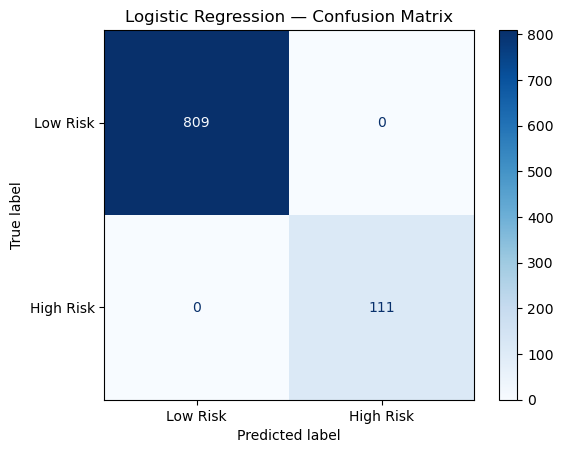

Type-I error (FP): 0 low-risk customers incorrectly flagged.
Type-II error (FN): 0 high-risk customers missed.


In [5]:
baseline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight=None, random_state=RANDOM_STATE))
])
baseline.fit(X_train, y_train)

def evaluate_model(name, fitted_model, X_eval=X_test, y_eval=y_test, threshold=0.5):
    probabilities = fitted_model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, predictions, labels=[0,1]).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision (High Risk)": precision_score(y_eval, predictions, zero_division=0),
        "Recall / TPR (High Risk)": recall_score(y_eval, predictions, zero_division=0),
        "F1 (High Risk)": f1_score(y_eval, predictions, zero_division=0),
        "FPR": fp/(fp+tn) if (fp+tn) else 0,
        "AUC-ROC": roc_auc_score(y_eval, probabilities),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }, probabilities, predictions

baseline_result, baseline_prob, baseline_pred = evaluate_model("Logistic Regression", baseline)
display(pd.DataFrame([baseline_result]).set_index("Model"))
print(classification_report(y_test, baseline_pred, target_names=["Low Risk", "High Risk"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_pred, display_labels=["Low Risk", "High Risk"], cmap="Blues"
)
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, baseline_pred, labels=[0,1]).ravel()
print(f"Type-I error (FP): {fp} low-risk customers incorrectly flagged.")
print(f"Type-II error (FN): {fn} high-risk customers missed.")

## Part D — Imbalance diagnosis and resampling comparison

The following methods are applied to the training data only, within an imbalanced-learn pipeline. This prevents information from the test set leaking into synthetic or sampled observations. The same Logistic Regression classifier is used to isolate the effect of resampling.

In [6]:
print("Training class counts:")
display(y_train.value_counts().sort_index().rename(index={0:"Low Risk",1:"High Risk"}).to_frame("count"))

samplers = {
    "No resampling": "passthrough",
    "Random Under-Sampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random Over-Sampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
    "ADASYN": ADASYN(random_state=RANDOM_STATE, n_neighbors=5)
}

sampling_models = {}
sampling_rows = []
for name, sampler in samplers.items():
    pipe = ImbPipeline([
        ("preprocess", preprocessor),
        ("sampler", sampler),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])
    try:
        pipe.fit(X_train, y_train)
        result, prob, pred = evaluate_model(name, pipe)
        sampling_models[name] = pipe
        sampling_rows.append(result)
    except ValueError as e:
        print(f"{name} skipped: {e}")

sampling_results = pd.DataFrame(sampling_rows).set_index("Model")
display(sampling_results[[
    "Accuracy", "Precision (High Risk)", "Recall / TPR (High Risk)", "F1 (High Risk)", "AUC-ROC", "FP", "FN"
]].sort_values("Recall / TPR (High Risk)", ascending=False))

Training class counts:


,count
risk_status,
Low Risk,3234
High Risk,446


  File "C:\Users\yakshrajsinh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\yakshrajsinh\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\yakshrajsinh\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\yakshrajsi

,Accuracy,Precision (High Risk),Recall / TPR (High Risk),F1 (High Risk),AUC-ROC,FP,FN
Model,,,,,,,
No resampling,1.000000,1.000000,1.0,1.000000,1.000000,0,0
Random Under-Sampling,0.996739,0.973684,1.0,0.986667,1.000000,3,0
Random Over-Sampling,0.997826,0.982301,1.0,0.991071,1.000000,2,0
SMOTE,0.997826,0.982301,1.0,0.991071,0.999989,2,0
ADASYN,0.997826,0.982301,1.0,0.991071,0.999978,2,0


### Interpreting the balancing experiment
Compare minority-class recall, F1 and AUC-ROC before and after balancing. Under-sampling may discard useful majority examples; over-sampling duplicates minority examples; SMOTE creates synthetic minority examples by interpolation; ADASYN creates more synthetic examples around harder-to-learn minority observations. Resampling does not guarantee improvement, so choose using held-out test metrics.

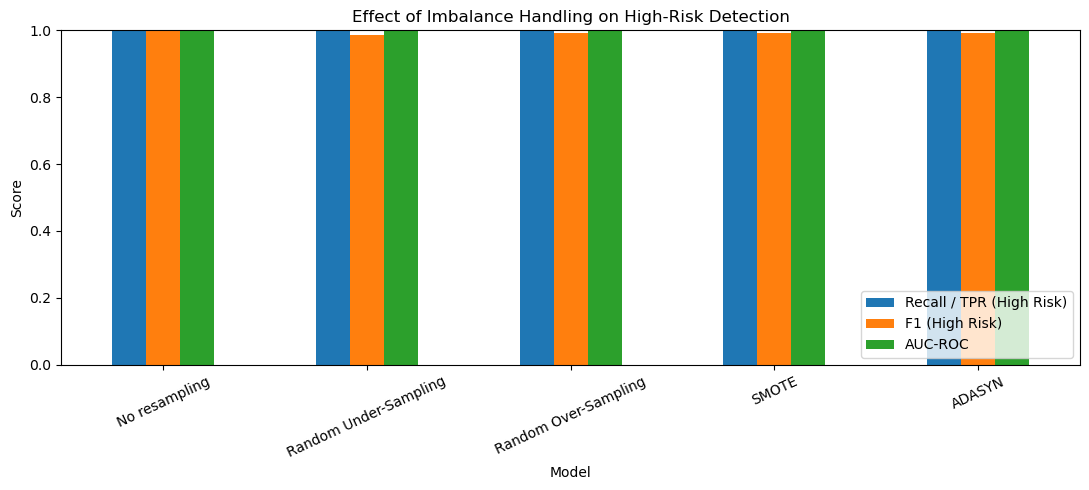

In [7]:
sampling_results[["Recall / TPR (High Risk)", "F1 (High Risk)", "AUC-ROC"]].plot(
    kind="bar", figsize=(11,5), ylim=(0,1), rot=25
)
plt.ylabel("Score")
plt.title("Effect of Imbalance Handling on High-Risk Detection")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Part E — Decision Tree and Random Forest

Training and test scores are compared to diagnose overfitting. A large training score with substantially lower test score suggests poor generalization.

In [8]:
tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])
forest = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
                                     class_weight="balanced"))
])
tree.fit(X_train, y_train)
forest.fit(X_train, y_train)

def train_test_summary(name, model):
    tr_prob = model.predict_proba(X_train)[:,1]
    te_prob = model.predict_proba(X_test)[:,1]
    tr_pred = (tr_prob >= .5).astype(int)
    te_pred = (te_prob >= .5).astype(int)
    return {
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, tr_pred),
        "Test Accuracy": accuracy_score(y_test, te_pred),
        "Train F1": f1_score(y_train, tr_pred, zero_division=0),
        "Test F1": f1_score(y_test, te_pred, zero_division=0),
        "Test Recall": recall_score(y_test, te_pred, zero_division=0),
        "Test AUC": roc_auc_score(y_test, te_prob)
    }

tree_forest_table = pd.DataFrame([
    train_test_summary("Decision Tree", tree),
    train_test_summary("Random Forest", forest)
]).set_index("Model")
display(tree_forest_table)

,Train Accuracy,Test Accuracy,Train F1,Test F1,Test Recall,Test AUC
Model,,,,,,
Decision Tree,1.0,0.966304,1.0,0.862222,0.873874,0.926430
Random Forest,1.0,0.994565,1.0,0.976959,0.954955,0.999955


## Part F — Hyperparameter tuning

RandomizedSearchCV is used first for broad exploration, with stratified folds and recall as the primary optimization metric. The best Random Forest configuration is then fine-tuned with GridSearchCV. The preprocessing remains inside the pipeline so each CV fold learns its own imputation and encoding parameters.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

tree_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])
tree_params = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__max_depth": [None, 3, 5, 8, 12, 16, 20],
    "model__min_samples_split": [2, 5, 10, 20, 40],
    "model__min_samples_leaf": [1, 2, 4, 8, 12],
    "model__class_weight": [None, "balanced"]
}
tree_random = RandomizedSearchCV(
    tree_pipe, tree_params, n_iter=25, scoring="recall",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
tree_random.fit(X_train, y_train)
print("Decision Tree best CV recall:", tree_random.best_score_)
print("Decision Tree best params:", tree_random.best_params_)

forest_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])
forest_params = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 5, 8, 12, 16, 24],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", 0.5],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}
forest_random = RandomizedSearchCV(
    forest_pipe, forest_params, n_iter=25, scoring="recall",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1
)
forest_random.fit(X_train, y_train)
print("Random Forest best CV recall:", forest_random.best_score_)
print("Random Forest best params:", forest_random.best_params_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Decision Tree best CV recall: 0.957478152309613
Decision Tree best params: {'model__min_samples_split': 40, 'model__min_samples_leaf': 12, 'model__max_depth': 16, 'model__criterion': 'log_loss', 'model__class_weight': 'balanced'}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
Random Forest best CV recall: 0.9641697877652934
Random Forest best params: {'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 8, 'model__max_features': 'sqrt', 'model__max_depth': 24, 'model__class_weight': 'balanced'}


### Grid Search fine-tuning of the best Random Forest
The grid is deliberately centered around the best randomized-search values to keep computation manageable. Adjust the neighboring values if your dataset is large or runtime is limited.

In [10]:
best_rf_params = forest_random.best_params_
def neighbors(value, choices):
    # Return a compact neighborhood that includes the randomized-search winner.
    if value not in choices:
        return [value]
    i = choices.index(value)
    return choices[max(0, i-1):min(len(choices), i+2)]

grid_params = {
    "model__n_estimators": neighbors(best_rf_params["model__n_estimators"], [200,300,500,700]),
    "model__max_depth": list(dict.fromkeys([best_rf_params["model__max_depth"], 8, 12, 16])),
    "model__min_samples_split": neighbors(best_rf_params["model__min_samples_split"], [2,5,10,20]),
    "model__min_samples_leaf": neighbors(best_rf_params["model__min_samples_leaf"], [1,2,4,8]),
    "model__max_features": [best_rf_params["model__max_features"]],
    "model__class_weight": [best_rf_params["model__class_weight"]]
}
rf_grid = GridSearchCV(
    forest_pipe, grid_params, scoring="recall", cv=cv, n_jobs=-1, verbose=1
)
rf_grid.fit(X_train, y_train)
print("Grid Search best CV recall:", rf_grid.best_score_)
print("Grid Search best params:", rf_grid.best_params_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Grid Search best CV recall: 0.9664169787765294
Grid Search best params: {'model__class_weight': 'balanced', 'model__max_depth': 24, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 8, 'model__min_samples_split': 20, 'model__n_estimators': 200}


## Part G — Final evaluation, threshold selection and ROC analysis

The default threshold is 0.50, but a bank may choose a lower threshold to reduce false negatives, accepting more false positives. The threshold below is selected on out-of-fold training predictions only, not on the test set. This avoids tuning the threshold against the final test labels.

In [11]:
from sklearn.model_selection import cross_val_predict

best_model = rf_grid.best_estimator_
# OOF probabilities for threshold selection using the tuned pipeline.
oof_prob = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:,1]

threshold_rows = []
for threshold in np.arange(0.10, 0.81, 0.05):
    pred = (oof_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold),2),
        "recall": recall_score(y_train, pred, zero_division=0),
        "precision": precision_score(y_train, pred, zero_division=0),
        "f1": f1_score(y_train, pred, zero_division=0)
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

# Illustrative policy: among thresholds with recall >= 0.90, choose highest precision.
eligible = threshold_table[threshold_table["recall"] >= 0.90]
if len(eligible):
    chosen_threshold = float(eligible.sort_values(["precision","f1"], ascending=False).iloc[0]["threshold"])
else:
    chosen_threshold = float(threshold_table.sort_values(["recall","f1"], ascending=False).iloc[0]["threshold"])
print("Chosen threshold from training OOF predictions:", chosen_threshold)

model_candidates = {
    "Logistic Regression": baseline,
    "Decision Tree": tree,
    "Random Forest": forest,
    "Tuned Decision Tree": tree_random.best_estimator_,
    "Tuned Random Forest": rf_grid.best_estimator_
}
all_rows = []
all_probs = {}
for name, model in model_candidates.items():
    res, prob, pred = evaluate_model(name, model)
    all_rows.append(res)
    all_probs[name] = prob

# Add tuned RF at the business-selected threshold separately.
tuned_prob = best_model.predict_proba(X_test)[:,1]
tuned_pred = (tuned_prob >= chosen_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, tuned_pred, labels=[0,1]).ravel()
threshold_result = {
    "Model": f"Tuned Random Forest (threshold={chosen_threshold:.2f})",
    "Accuracy": accuracy_score(y_test, tuned_pred),
    "Precision (High Risk)": precision_score(y_test, tuned_pred, zero_division=0),
    "Recall / TPR (High Risk)": recall_score(y_test, tuned_pred, zero_division=0),
    "F1 (High Risk)": f1_score(y_test, tuned_pred, zero_division=0),
    "FPR": fp/(fp+tn) if (fp+tn) else 0,
    "AUC-ROC": roc_auc_score(y_test, tuned_prob),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp
}
comparison = pd.DataFrame(all_rows + [threshold_result]).set_index("Model")
display(comparison.sort_values(["Recall / TPR (High Risk)", "F1 (High Risk)"], ascending=False))

,threshold,recall,precision,f1
0,0.10,0.997758,0.380017,0.550402
1,0.15,0.997758,0.505682,0.671192
2,0.20,0.993274,0.606849,0.753401
3,0.25,0.988789,0.712439,0.828169
4,0.30,0.986547,0.776014,0.868707
5,0.35,0.984305,0.837786,0.905155
6,0.40,0.977578,0.895277,0.934620
7,0.45,0.973094,0.931330,0.951754
8,0.50,0.966368,0.959911,0.963128
9,0.55,0.952915,0.968109,0.960452


Chosen threshold from training OOF predictions: 0.65


,Accuracy,Precision (High Risk),Recall / TPR (High Risk),F1 (High Risk),FPR,AUC-ROC,TN,FP,FN,TP
Model,,,,,,,,,,
Logistic Regression,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,809,0,0,111
Tuned Random Forest,0.995652,0.973451,0.990991,0.982143,0.003708,0.999922,806,3,1,110
Tuned Decision Tree,0.966304,0.789855,0.981982,0.875502,0.035847,0.990969,780,29,2,109
Tuned Random Forest (threshold=0.65),0.995652,1.000000,0.963964,0.981651,0.000000,0.999922,809,0,4,107
Random Forest,0.994565,1.000000,0.954955,0.976959,0.000000,0.999955,809,0,5,106
Decision Tree,0.966304,0.850877,0.873874,0.862222,0.021014,0.926430,792,17,14,97


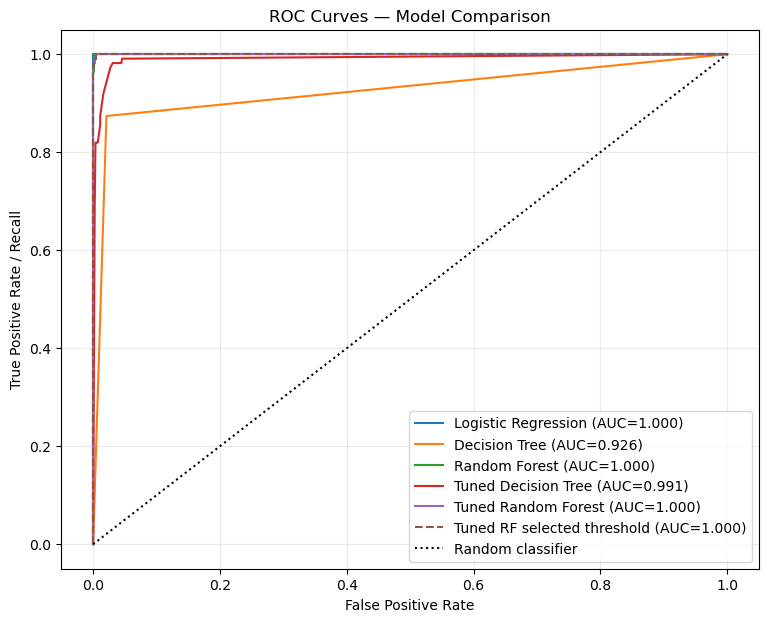

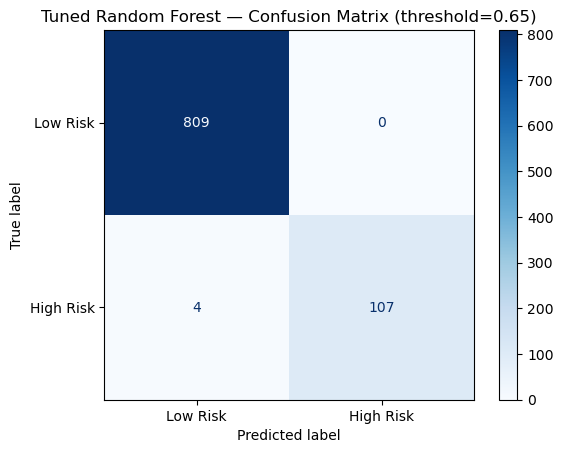

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      0.96      0.98       111

    accuracy                           1.00       920
   macro avg       1.00      0.98      0.99       920
weighted avg       1.00      1.00      1.00       920

Final Type-I error (FP): 0
Final Type-II error (FN): 4


In [13]:
plt.figure(figsize=(9,7))
for name, prob in all_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
fpr, tpr, _ = roc_curve(y_test, tuned_prob)
plt.plot(fpr, tpr, linestyle="--", label=f"Tuned RF selected threshold (AUC={roc_auc_score(y_test,tuned_prob):.3f})")
plt.plot([0,1], [0,1], "k:", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curves — Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=.25)
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, display_labels=["Low Risk", "High Risk"], cmap="Blues"
)
plt.title(f"Tuned Random Forest — Confusion Matrix (threshold={chosen_threshold:.2f})")
plt.show()

print(classification_report(y_test, tuned_pred, target_names=["Low Risk", "High Risk"], zero_division=0))
print(f"Final Type-I error (FP): {fp}")
print(f"Final Type-II error (FN): {fn}")

## Part H — Final report and business recommendations

Use the actual outputs above to complete this section after running the notebook.

### Best model selection
Select the model that achieves the strongest high-risk recall while maintaining a usable precision/FPR and competitive F1/AUC. Because the business requirement emphasizes minimizing false negatives, do not select solely by accuracy. The threshold can be lowered to flag more potentially risky customers, but this increases false positives and the workload for manual review.

### Impact of imbalance handling
Report the test-set changes in high-risk recall, F1 and ROC-AUC for under-sampling, over-sampling, SMOTE and ADASYN. Explain which approach best detects risky customers and whether it creates an unacceptable increase in false positives. The untouched test set must remain at its original class distribution.

### Business interpretation
- **False negative:** a risky customer is missed; potential losses from default/fraud may go undetected.
- **False positive:** a low-risk customer is flagged; the bank may incur investigation costs or create unnecessary friction.
- A practical deployment should route flagged accounts to proportionate verification or human review rather than automatically penalizing customers.

### Recommendations
1. Monitor recall, precision, FPR and calibration over time; customer behavior and fraud patterns can drift.
2. Set the operating threshold according to the bank's investigation capacity and relative cost of missed risk versus false alarms.
3. Validate fairness and stability across relevant customer groups before deployment.
4. Retrain periodically and evaluate on a later time-based holdout where possible.
5. Treat model outputs as decision support, with human review and documented governance.


